# Sécurité routière en Grande-Bretagne — compréhension des données

**Projet d’équipe · STATS19 · période 2021–2025**

Ce notebook établit le contexte métier, décrit les tables, contrôle leur qualité et produit des indicateurs exploratoires. Les résultats portent sur les collisions corporelles enregistrées par la police, et non sur le risque par trajet.

**Équipe :** Oussema Sahbeni · Aziz Zina · Mahdi Zaied · Omar Mseddi · Youssef Takeli


## 1. Compréhension métier et objectifs du projet

**Objectif 1 réalisé :** classifier la gravité enregistrée d’une collision (mortelle, grave, légère) à partir du contexte et des véhicules. Unité : une collision ; la cible est la gravité de sa victime la plus sévèrement touchée. Le résultat est académique et conditionnel à un événement déjà déclaré.

**Objectif 2 prévu :** classer la gravité individuelle d’une victime, en utilisant son profil et le contexte. **Objectif 3 prévu :** estimer le nombre de victimes par collision. Ces deux objectifs ne sont pas implémentés à ce stade, conformément au périmètre demandé.

Les acteurs concernés sont les autorités de transport, autorités locales, chercheurs et professionnels de sécurité routière. L’analyse sert à comprendre des associations et à évaluer un modèle, pas à attribuer une responsabilité ou annoncer une cause.

Le succès de l’objectif 1 se juge au F1 macro sur validation 2024, face à une référence majoritaire, puis sur les erreurs de chaque classe en 2025. Les paramètres sont réglés sur validation et les cas rares sont conservés. La préparation est documentée dans le notebook 02 et les expériences comparées dans le notebook 03.


## 2. Origine, périmètre et modèle des données

Source : [DfT — Road safety open data](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data). Les trois fichiers « last 5 years » correspondent à 2021–2025 et totalisent environ **254 Mo** selon les tailles arrondies de la page officielle et **255,1 Mo** pour la copie locale téléchargée (octets décimaux, consulté le 24 octobre 2026). Le classeur de décodage DfT est fourni dans `references/data_guide_2025.xlsx`.

| Table | Unité d’observation | Clé de liaison | Taille annoncée |
|---|---|---|---:|
| Collisions | Une collision corporelle | `collision_index` | 97,7 Mo |
| Véhicules | Un véhicule impliqué | `collision_index` + `vehicle_reference` | 103,7 Mo |
| Victimes | Une victime | `collision_index` + `vehicle_reference` + `casualty_reference` | 52,4 Mo |

La portée est limitée aux collisions corporelles sur voies publiques, déclarées à la police et enregistrées sous STATS19. Les collisions sans blessé, les incidents non signalés et les voies privées ne sont pas couverts. Les champs catégoriels sont en grande partie codés : se reporter au [guide officiel des données](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data) et aux [notes de couverture et de qualité](https://www.gov.uk/government/publications/road-accidents-and-safety-statistics-notes-and-definitions/road-casualty-statistics-overview-and-coverage) avant toute interprétation.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
from pathlib import Path
ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / "notebooks").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None: raise RuntimeError("Ouvrir ce notebook depuis le dossier road-safety-project ou son sous-dossier notebooks.")
RAW = ROOT / "data/raw"
PROCESSED = ROOT / "data/processed"
print(f"Racine du projet : {ROOT}")

Racine du projet : C:\Users\omarm\Downloads\road-safety-project


### Téléchargement reproductible

Les CSV bruts sont volontairement ignorés par Git. Si un fichier manque, le code de téléchargement ci-dessous récupère les trois sources DfT officielles.


In [2]:
from urllib.request import urlretrieve
BASE = "https://data.dft.gov.uk/road-accidents-safety-data"
FILES = {
    "collisions_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-collision-last-5-years.csv",
    "vehicles_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-vehicle-last-5-years.csv",
    "casualties_2021_2025.csv": f"{BASE}/dft-road-casualty-statistics-casualty-last-5-years.csv",
}
def download_all(force: bool = False) -> None:
    RAW.mkdir(parents=True, exist_ok=True)
    for filename, url in FILES.items():
        destination = RAW / filename
        if destination.exists() and destination.stat().st_size > 0 and not force:
            print(f"Déjà présent : {destination.name} ({destination.stat().st_size / 1_000_000:.1f} Mo)")
            continue
        print(f"Téléchargement : {filename}")
        urlretrieve(url, destination)
        if destination.stat().st_size == 0:
            destination.unlink(missing_ok=True)
            raise RuntimeError(f"Fichier vide reçu depuis {url}")
        print(f"Terminé : {destination.stat().st_size / 1_000_000:.1f} Mo")

expected = [
    RAW / "collisions_2021_2025.csv",
    RAW / "vehicles_2021_2025.csv",
    RAW / "casualties_2021_2025.csv",
]
if not all(path.exists() and path.stat().st_size > 0 for path in expected):
    download_all()

for path in expected:
    print(f"{path.name}: {path.stat().st_size / 1_000_000:.1f} Mo")

collisions_2021_2025.csv: 97.7 Mo
vehicles_2021_2025.csv: 103.7 Mo
casualties_2021_2025.csv: 53.7 Mo


## 3. Chargement et premier aperçu

Les colonnes restent principalement en valeurs brutes afin d’éviter de transformer les codes avant de consulter leur dictionnaire.


In [3]:
collisions = pd.read_csv(RAW / "collisions_2021_2025.csv", low_memory=False)
vehicles = pd.read_csv(RAW / "vehicles_2021_2025.csv", low_memory=False)
casualties = pd.read_csv(RAW / "casualties_2021_2025.csv", low_memory=False)

tables = {"Collisions": collisions, "Véhicules": vehicles, "Victimes": casualties}
summary = pd.DataFrame([
    {"Table": name, "Lignes": len(df), "Colonnes": df.shape[1], "Mémoire (Mo)": round(df.memory_usage(deep=True).sum() / 1_000_000, 1)}
    for name, df in tables.items()
])
display(summary)
print("Champs collisions :", collisions.columns.tolist())
print("Champs véhicules :", vehicles.columns.tolist())
print("Champs victimes :", casualties.columns.tolist())
observed_years = sorted(collisions["collision_year"].dropna().astype(int).unique().tolist())
expected_years = [2021, 2022, 2023, 2024, 2025]
if observed_years != expected_years:
    raise ValueError(f"L’URL DfT « last 5 years » a évolué : années reçues {observed_years}, attendues {expected_years}. Mettre à jour les URL et renommer les fichiers avant l’analyse.")


,Table,Lignes,Colonnes,Mémoire (Mo)
0,Collisions,513801,44,419.6
1,Véhicules,937265,32,460.8
2,Victimes,652821,24,240.9


Champs collisions : ['collision_index', 'collision_year', 'collision_ref_no', 'location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude', 'police_force', 'collision_severity', 'number_of_vehicles', 'number_of_casualties', 'date', 'day_of_week', 'time', 'local_authority_district', 'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current', 'first_road_class', 'first_road_number', 'road_type', 'speed_limit', 'junction_detail_historic', 'junction_detail', 'junction_control', 'second_road_class', 'second_road_number', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'pedestrian_crossing', 'light_conditions', 'weather_conditions', 'road_surface_conditions', 'special_conditions_at_site', 'carriageway_hazards_historic', 'carriageway_hazards', 'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident', 'trunk_road_flag', 'lsoa_of_accident_location', 'enhanced_severity_collision', 'colli

## 4. Qualité, identifiants et relations

On vérifie la disponibilité des clés, les doublons et la cohérence entre les identifiants des tables. Les éventuels écarts sont à documenter avant une analyse plus poussée.


In [4]:
key_checks = []
for name, df in tables.items():
    key_checks.append({
        "Table": name,
        "Clé collision présente": "collision_index" in df.columns,
        "Lignes sans clé collision": int(df["collision_index"].isna().sum()) if "collision_index" in df else np.nan,
        "Collision_index distincts": int(df["collision_index"].nunique()) if "collision_index" in df else np.nan,
    })
display(pd.DataFrame(key_checks))

if "collision_index" in collisions:
    print("Doublons de collision_index dans collisions :", int(collisions["collision_index"].duplicated().sum()))
collision_keys = set(collisions["collision_index"].dropna())
for name, df in [("Véhicules", vehicles), ("Victimes", casualties)]:
    orphan = int((~df["collision_index"].isin(collision_keys)).sum())
    print(f"{name} sans collision correspondante : {orphan:,} lignes ({orphan / max(1, len(df)):.2%})")

missingness = pd.concat({name: df.isna().mean().mul(100) for name, df in tables.items()}, axis=1)
for name in missingness:
    print()
    print(f"{name} — 15 champs avec le plus de valeurs manquantes (%)")
    display(missingness[name].sort_values(ascending=False).head(15).round(1).to_frame("Manquants %"))

,Table,Clé collision présente,Lignes sans clé collision,Collision_index distincts
0,Collisions,True,0,513801
1,Véhicules,True,0,513801
2,Victimes,True,0,513801


Doublons de collision_index dans collisions : 0
Véhicules sans collision correspondante : 0 lignes (0.00%)
Victimes sans collision correspondante : 0 lignes (0.00%)

Collisions — 15 champs avec le plus de valeurs manquantes (%)


,Manquants %
location_easting_osgr,0.0
latitude,0.0
longitude,0.0
location_northing_osgr,0.0
collision_ref_no,0.0
collision_year,0.0
collision_index,0.0
police_force,0.0
collision_severity,0.0
number_of_vehicles,0.0



Véhicules — 15 champs avec le plus de valeurs manquantes (%)


,Manquants %
collision_index,0.0
collision_year,0.0
collision_ref_no,0.0
vehicle_reference,0.0
vehicle_type,0.0
towing_and_articulation,0.0
vehicle_manoeuvre_historic,0.0
vehicle_manoeuvre,0.0
vehicle_direction_from,0.0
vehicle_direction_to,0.0



Victimes — 15 champs avec le plus de valeurs manquantes (%)


,Manquants %
collision_index,0.0
collision_year,0.0
collision_ref_no,0.0
vehicle_reference,0.0
escooter_flag,0.0
casualty_reference,0.0
casualty_class,0.0
sex_of_casualty,0.0
age_of_casualty,0.0
age_band_of_casualty,0.0


### Contrôle des comptes victimes

Le nombre de lignes de la table victimes par collision peut être comparé au champ de comptage de la table collisions lorsqu’il existe. Un écart n’est pas automatiquement une erreur : il peut révéler des problèmes de clé, de version ou de couverture.


In [5]:
if {"number_of_casualties", "collision_index"}.issubset(collisions.columns):
    casualties_per_collision = casualties.groupby("collision_index").size().rename("victimes_calculees")
    comparison = collisions[["collision_index", "number_of_casualties"]].merge(
        casualties_per_collision, left_on="collision_index", right_index=True, how="left"
    )
    comparison["victimes_calculees"] = comparison["victimes_calculees"].fillna(0)
    comparison["ecart"] = comparison["number_of_casualties"] - comparison["victimes_calculees"]
    print("Part des collisions avec comptage concordant :", f"{(comparison['ecart'] == 0).mean():.2%}")
    display(comparison.loc[comparison["ecart"] != 0].head(10))
else:
    print("Le champ number_of_casualties n’est pas disponible dans cette version du fichier.")

Part des collisions avec comptage concordant : 100.00%


,collision_index,number_of_casualties,victimes_calculees,ecart


## 5. Évolution observée

Le nombre d’enregistrements n’est pas un taux de risque : il n’est pas rapporté à la circulation, aux kilomètres parcourus ou au nombre de déplacements. Les ruptures de déclaration et de mesure de la gravité limitent aussi les comparaisons dans le temps.


,Collisions enregistrées,Victimes enregistrées
collision_year,,
2021,101087,128209
2022,106004,135480
2023,104258,132977
2024,100927,128272
2025,101525,127883


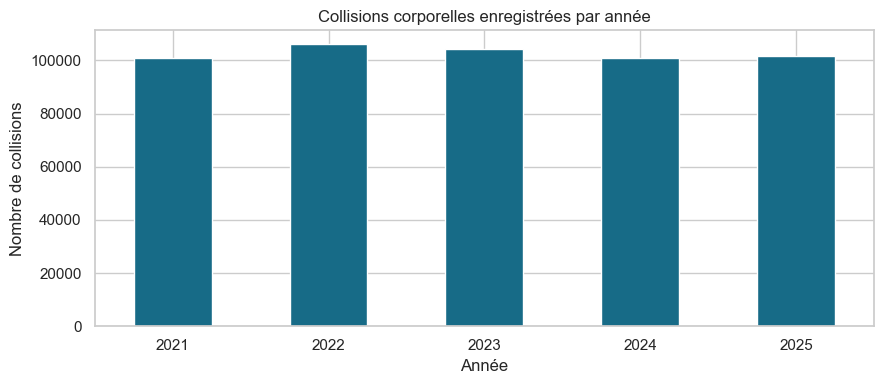

In [6]:
year_col = "collision_year" if "collision_year" in collisions.columns else None
if year_col:
    annual_collisions = collisions.groupby(year_col).size().rename("Collisions enregistrées")
    annual_casualties = casualties.groupby("collision_year").size().rename("Victimes enregistrées") if "collision_year" in casualties.columns else pd.Series(dtype=int)
    display(pd.concat([annual_collisions, annual_casualties], axis=1).fillna(0).astype(int))
    ax = annual_collisions.plot(kind="bar", figsize=(9, 4), color="#176B87")
    ax.set(title="Collisions corporelles enregistrées par année", xlabel="Année", ylabel="Nombre de collisions")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()
else:
    print("Aucun champ annuel détecté.")

## 6. Gravité des conséquences

Le code STATS19 standard distingue les collisions mortelles, graves et légères (`collision_severity` : 1, 2, 3). Vérifier le guide officiel de la version avant de figer cette interprétation. Depuis certaines années, la déclaration fondée sur les blessures a modifié la mesure de la gravité ; le DfT fournit des variables d’ajustement dans les fichiers récents.


collision_severity,Mortelle (code 1),Grave (code 2),Légère (code 3)
collision_year,,,
2021,1474,21284,78329
2022,1602,23333,81069
2023,1522,23438,79298
2024,1502,23567,75858
2025,1453,25191,74881


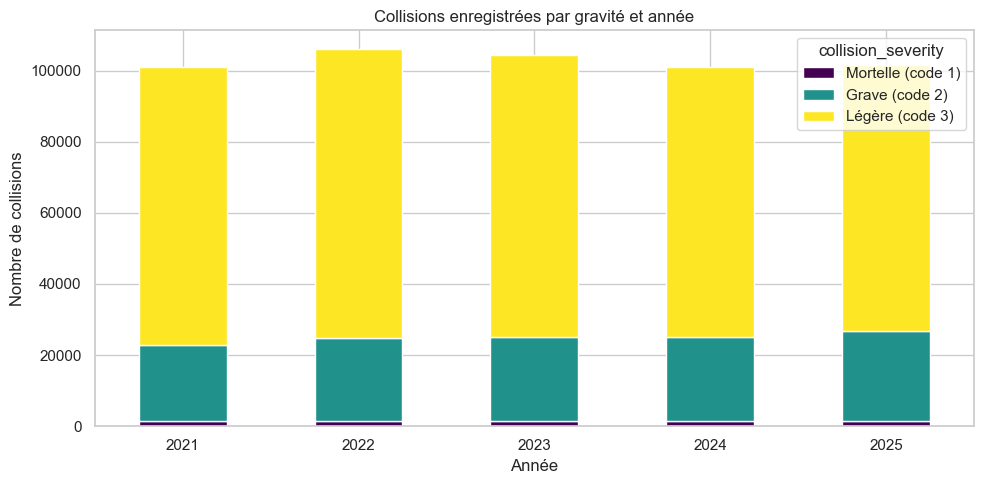

,Victimes par code de gravité
casualty_severity,
1,8033
2,129011
3,515777


,Graves ajustées,Légères ajustées
collision_year,,
2021,22658,76955
2022,24627,79775
2023,24644,78092
2024,24693,74732
2025,25743,74329


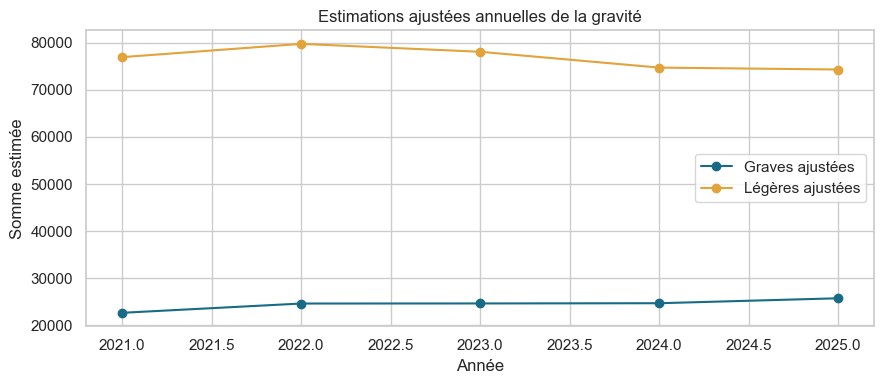

In [7]:
severity_labels = {1: "Mortelle (code 1)", 2: "Grave (code 2)", 3: "Légère (code 3)"}
if {"collision_year", "collision_severity"}.issubset(collisions.columns):
    severity_by_year = pd.crosstab(collisions["collision_year"], collisions["collision_severity"]).rename(columns=severity_labels)
    display(severity_by_year)
    severity_by_year.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="viridis")
    plt.title("Collisions enregistrées par gravité et année"); plt.xlabel("Année"); plt.ylabel("Nombre de collisions"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
else:
    print("Colonnes de gravité ou d’année non détectées : adapter l’analyse au guide de données.")

if "casualty_severity" in casualties.columns:
    display(casualties["casualty_severity"].value_counts(dropna=False).sort_index().rename("Victimes par code de gravité").to_frame())

adjusted_columns = ["collision_adjusted_severity_serious", "collision_adjusted_severity_slight"]
if set(adjusted_columns).issubset(collisions.columns):
    adjusted_annual = collisions.groupby("collision_year")[adjusted_columns].sum().round().astype(int)
    adjusted_annual = adjusted_annual.rename(columns={
        "collision_adjusted_severity_serious": "Graves ajustées",
        "collision_adjusted_severity_slight": "Légères ajustées",
    })
    display(adjusted_annual)
    adjusted_annual.plot(marker="o", figsize=(9, 4), color=["#176B87", "#E2A33B"])
    plt.title("Estimations ajustées annuelles de la gravité")
    plt.xlabel("Année"); plt.ylabel("Somme estimée")
    plt.tight_layout(); plt.show()
else:
    print("Variables de gravité ajustée non présentes ; consulter le guide DfT de la version téléchargée.")


## 7. Temporalité et contexte routier

Ces tableaux servent à repérer des distributions à étudier. Les variables de météo, de lumière, de route et de contrôle sont codées : ne pas leur attribuer de libellé sans consulter le guide.


,Collisions
Heure,
0,8110
1,5610
2,4106
3,3424
4,3138
5,4798
6,9561
7,20613
8,32860


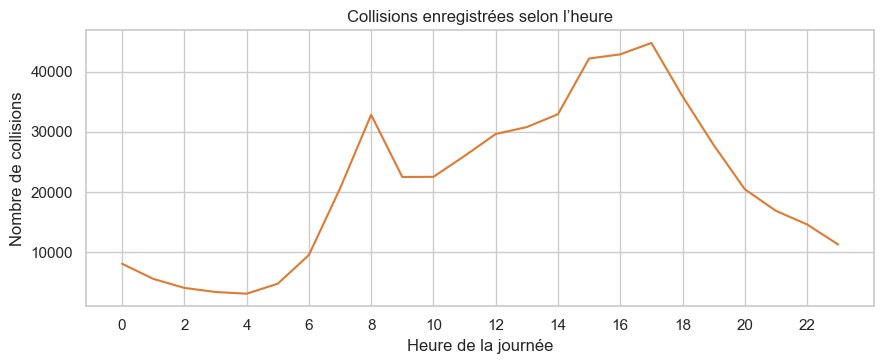


Répartition brute — light_conditions


,Nombre
Code,
1,368193
4,105834
6,27438
7,8596
5,3706
-1,34



Répartition brute — weather_conditions


,Nombre
Code,
1,413632
2,55834
8,15955
9,14566
5,5173
4,4472
7,2128
3,1791
6,238



Répartition brute — road_surface_conditions


,Nombre
Code,
1,374268
2,120572
9,6721
4,6668
-1,3527
3,1257
5,788



Répartition brute — urban_or_rural_area


,Nombre
Code,
1,345314
2,168429
3,50
-1,8



Répartition brute — speed_limit


,Nombre
Code,
30,267325
20,88096
60,62703
40,44750
70,28258
50,22666
-1,3


In [8]:
if "time" in collisions.columns:
    hour = pd.to_datetime(collisions["time"].astype(str), format="%H:%M", errors="coerce").dt.hour
    hourly = hour.value_counts().sort_index()
    display(hourly.rename_axis("Heure").to_frame("Collisions"))
    hourly.plot(figsize=(9, 3.8), color="#E07A32")
    plt.title("Collisions enregistrées selon l’heure"); plt.xlabel("Heure de la journée"); plt.ylabel("Nombre de collisions"); plt.xticks(range(0, 24, 2)); plt.tight_layout(); plt.show()

for column in ["light_conditions", "weather_conditions", "road_surface_conditions", "urban_or_rural_area", "speed_limit"]:
    if column in collisions.columns:
        print()
        print(f"Répartition brute — {column}")
        display(collisions[column].value_counts(dropna=False).head(15).rename_axis("Code").to_frame("Nombre"))

## 8. Lecture métier et prochaines étapes

### Ce que l’analyse descriptive peut apporter
- décrire les volumes enregistrés et leur évolution ;
- orienter une exploration locale selon la gravité, la période ou les conditions ;
- identifier des variables et des contrôles de qualité à approfondir.

### Ce qu’elle ne peut pas conclure seule
- qu’un facteur provoque une collision ;
- qu’un lieu, une heure ou un mode est plus dangereux sans dénominateur d’exposition ;
- que les changements du nombre de collisions traduisent directement un changement du risque.

### Suite proposée
1. Décoder les modalités avec le guide DfT et consigner les ruptures de définition.
2. Relier les collisions à des données d’exposition (trafic, population, kilomètres parcourus) et à des référentiels géographiques.
3. Valider les pistes avec des spécialistes locaux avant de proposer une intervention.

**Sources :** DfT, [Road safety open data](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data) ; [road casualty statistics: overview and coverage](https://www.gov.uk/government/publications/road-accidents-and-safety-statistics-notes-and-definitions/road-casualty-statistics-overview-and-coverage) ; [STATS20](https://www.gov.uk/government/publications/stats20-instructions-for-the-completion-of-road-accident-reports).
